In [1]:
!git clone https://github.com/ultralytics/yolov5

Cloning into 'yolov5'...
remote: Enumerating objects: 18806, done.
remote: Counting objects: 100% (358/358), done.
remote: Compressing objects: 100% (215/215), done.
remote: Total 18806 (delta 298), reused 143 (delta 143), pack-reused 18448 (from 2)
Receiving objects: 100% (18806/18806), 17.75 MiB | 17.55 MiB/s, done.
Resolving deltas: 100% (12819/12819), done.


In [2]:
%cd /content/yolov5
%pip install -qr requirements.txt

/content/yolov5


In [3]:
import torch

print("PyTorch版本：", torch.__version__)
print("GPU是否可使用：", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU名稱：", torch.cuda.get_device_name(0))

PyTorch版本： 2.11.0+cu130
GPU是否可使用： True
GPU名稱： Tesla T4


In [5]:
%cd /content/yolov5

!python detect.py \
  --weights yolov5s.pt \
  --source data/images \
  --img 640 \
  --conf 0.25

/content/yolov5
Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
detect: weights=['yolov5s.pt'], source=data/images, data=data/coco128.yaml, imgsz=[640, 640], conf_thres=0.25, iou_thres=0.45, max_det=1000, device=, view_img=False, save_txt=False, save_format=0, save_csv=False, save_conf=False, save_crop=False, nosave=False, classes=None, agnostic_nms=False, augment=False, update=False, project=runs/detect, name=exp, exist_ok=False, line_thickness=3, hide_labels=False, hide_conf=False, half=False, dnn=False, vid_stride=1
YOLOv5 🚀 v7.0-561-gaf08ba15 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)

100% 14.1M/14.1M [00:00<00:00, 165MB/s]

Fusing layers... 
YOLOv5s summary: 124 layers, 7,225,885 parameters, 0 gradients, 16.4 GFLOPs
imag

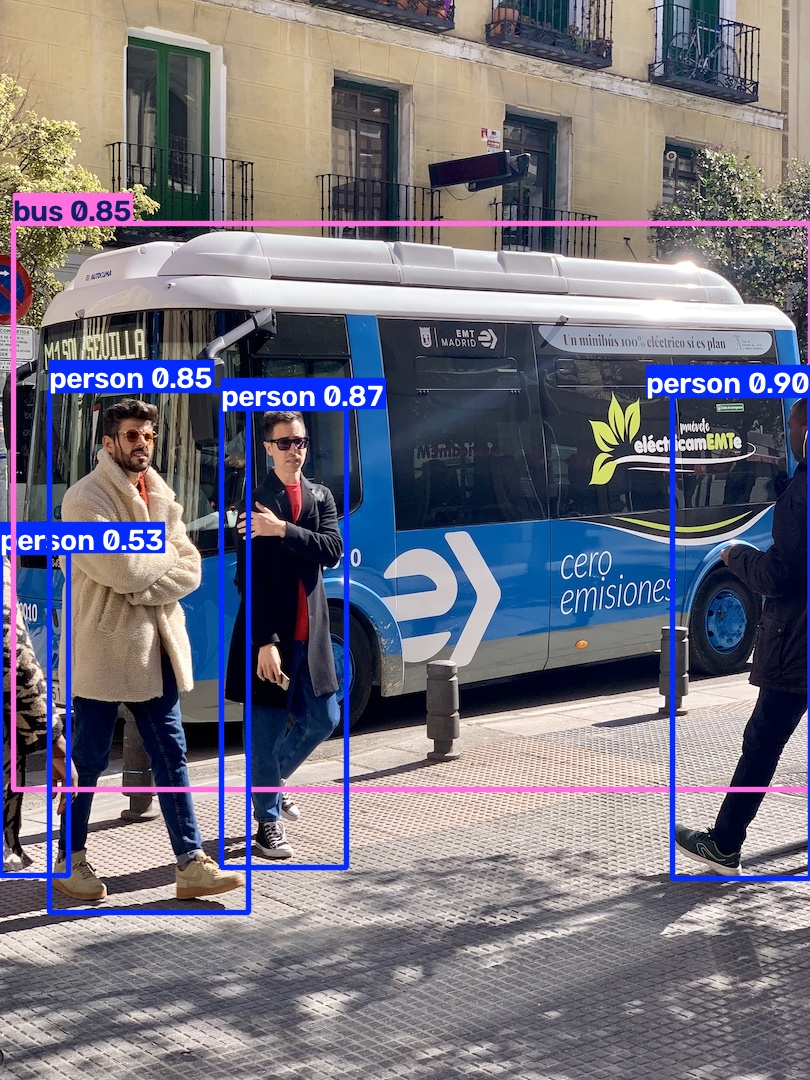

In [7]:
from IPython.display import Image, display
import glob
import os

files = glob.glob(
    "/content/yolov5/runs/detect/exp*/*.jpg"
)

if files:
    display(Image(filename=files[-1]))
else:
    print("請先確認 detect.py 已執行成功")

In [8]:
%cd /content/yolov5

!python train.py \
  --img 640 \
  --batch 16 \
  --epochs 3 \
  --data coco128.yaml \
  --weights yolov5s.pt \
  --name midterm_train

/content/yolov5
WARNING ⚠️ wandb: wandb is deprecated and will be removed in a future release. See supported integrations at https://github.com/ultralytics/yolov5#integrations.
I0000 00:00:1793287096.681111    3732 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
wandb: (1) Create a W&B account
wandb: (2) Use an existing W&B account
wandb: (3) Don't visualize my results
wandb: Enter your choice: (30 second timeout) 
wandb: WARNING W&B disabled due to login timeout.
wandb: W&B API key is configured. Use `wandb login --relogin` to force relogin
train: weights=yolov5s.pt, cfg=, data=coco128.yaml, hyp=data/hyps/hyp.scratch-low.yaml, epochs=3, batch_size=16, imgsz=640, rect=False, resume=False, nosave=False, noval=False, noautoanchor=False, noplots=False, evolve=None, evolve_population=data/hyps, resume_evolve=None, bucket=, cache=None, image_weights=False, device=, multi_scale=False, single_cls=False, optimizer=SGD, sync_bn=False, workers=8, project=run

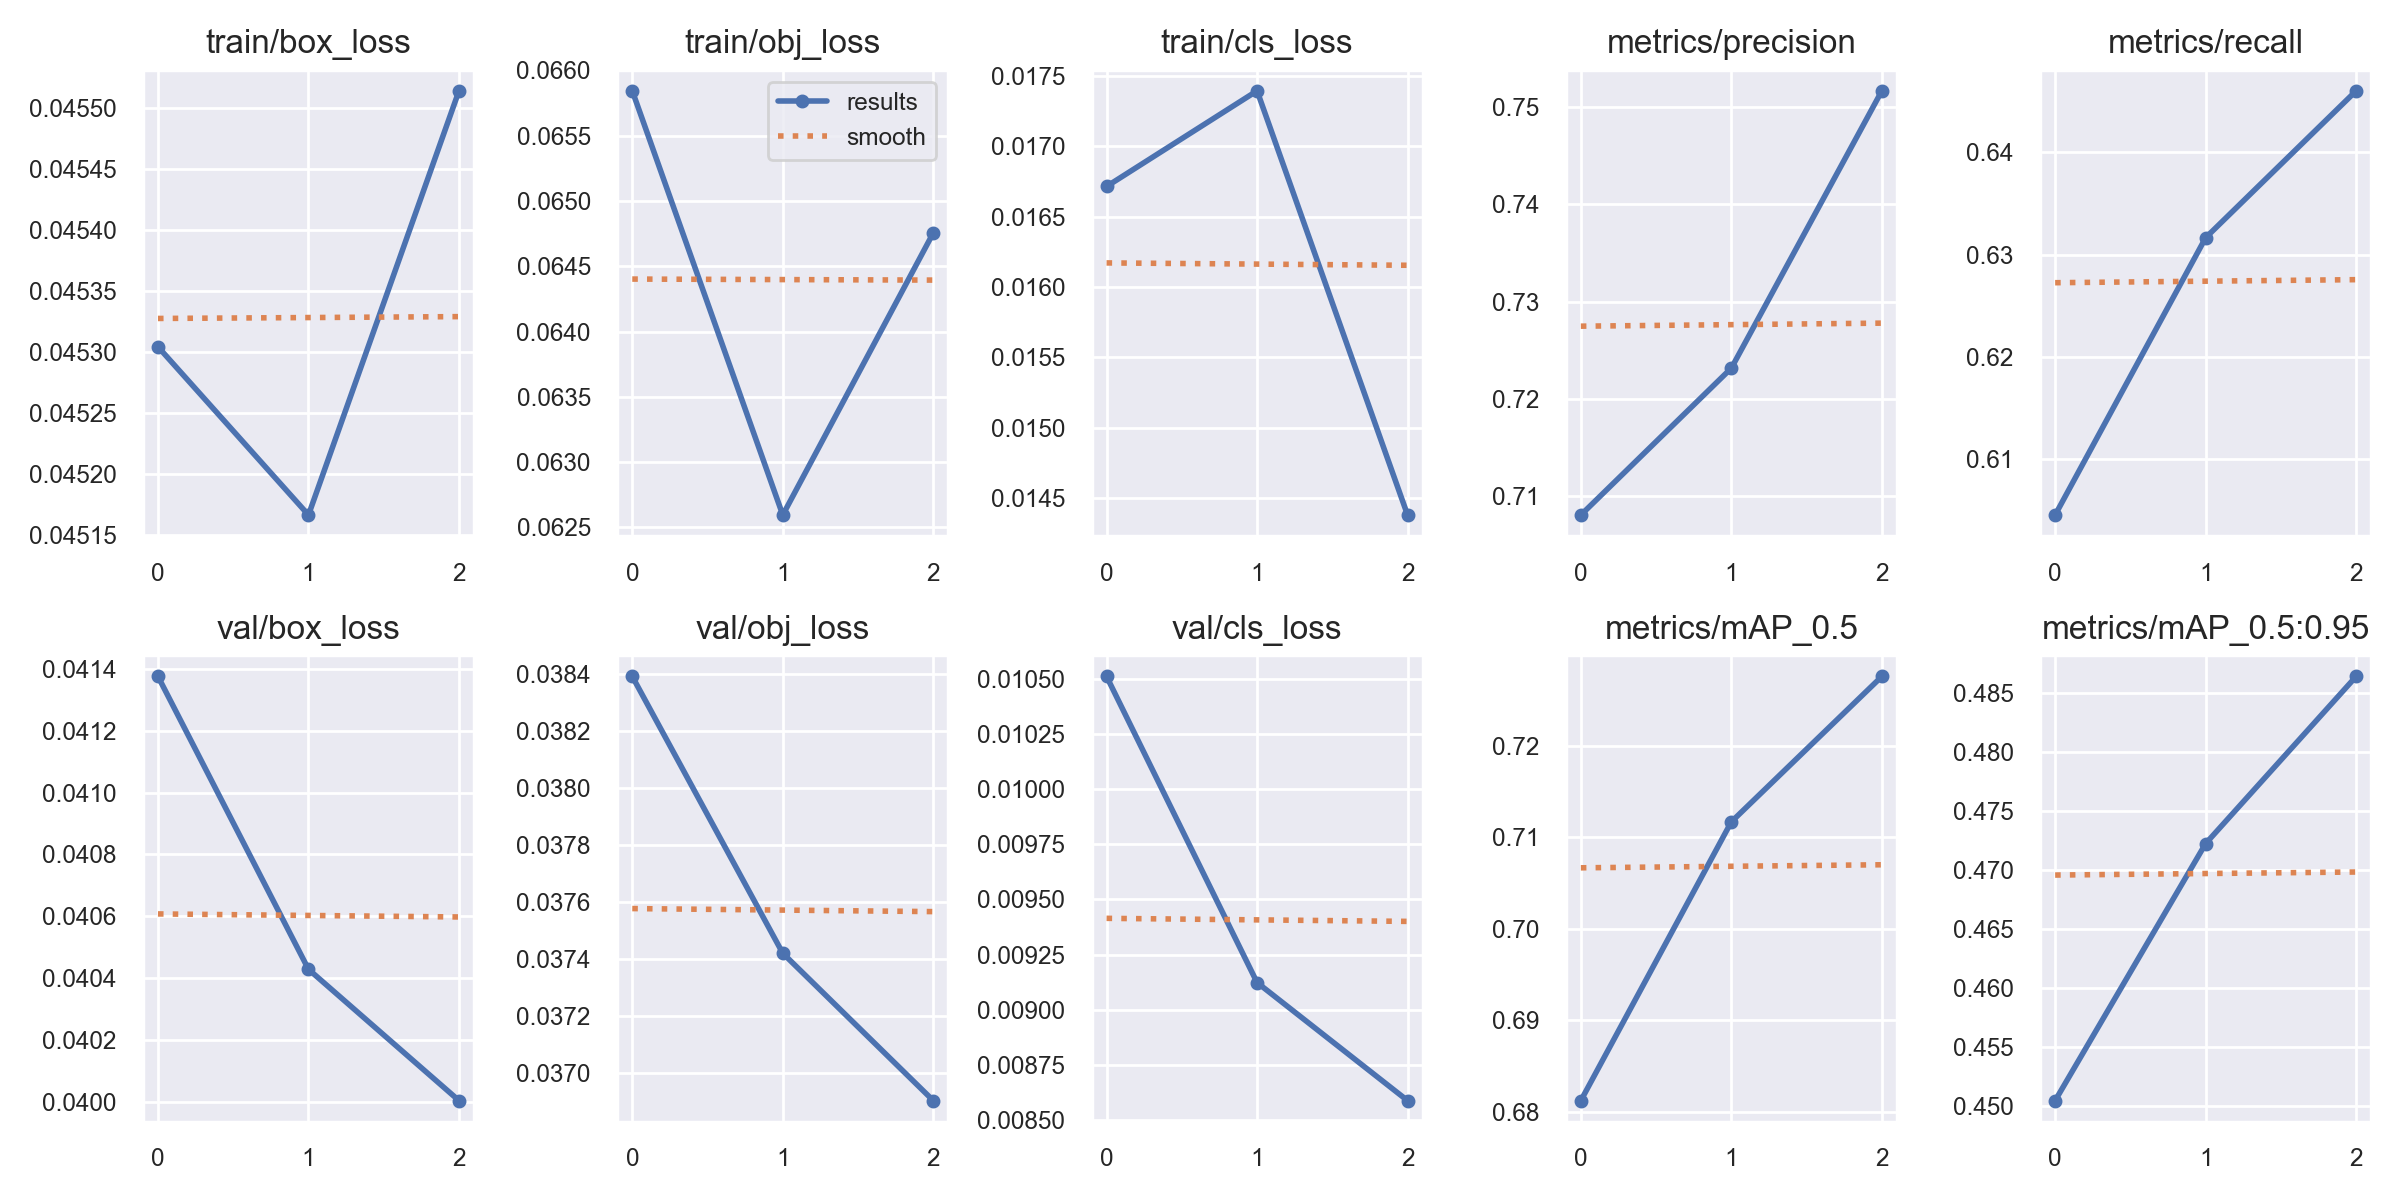

In [9]:
from IPython.display import Image, display
import os

result_path = (
    "/content/yolov5/runs/train/midterm_train/results.png"
)

if os.path.exists(result_path):
    display(Image(filename=result_path))
else:
    print("尚未找到 results.png，請確認訓練是否完成")

In [10]:
%cd /content/yolov5

!python detect.py \
  --weights runs/train/midterm_train/weights/best.pt \
  --source data/images \
  --img 640 \
  --conf 0.25 \
  --name midterm_predict

/content/yolov5
detect: weights=['runs/train/midterm_train/weights/best.pt'], source=data/images, data=data/coco128.yaml, imgsz=[640, 640], conf_thres=0.25, iou_thres=0.45, max_det=1000, device=, view_img=False, save_txt=False, save_format=0, save_csv=False, save_conf=False, save_crop=False, nosave=False, classes=None, agnostic_nms=False, augment=False, update=False, project=runs/detect, name=midterm_predict, exist_ok=False, line_thickness=3, hide_labels=False, hide_conf=False, half=False, dnn=False, vid_stride=1
YOLOv5 🚀 v7.0-561-gaf08ba15 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)

Fusing layers... 
Model summary: 68 layers, 7,225,885 parameters, 0 gradients, 16.4 GFLOPs
image 1/2 /content/yolov5/data/images/bus.jpg: 640x480 4 persons, 1 bus, 1 tie, 27.2ms
image 2/2 /content/yolov5/data/images/zidane.jpg: 384x640 2 persons, 2 ties, 29.4ms
Speed: 0.5ms pre-process, 28.3ms inference, 31.2ms NMS per image at shape (1, 3, 640, 640)
Results saved to runs/detect/midterm_